In [1]:
import requests
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from wordcloud import WordCloud
import time

## Data Collection
It is the systematic process of gathering information from various sources to answer research questions, evaluate outcomes, identify trends and make informed decisions. Collecting data from an API involves making requests to the API's endpoints and processing the returned data.

In [4]:
api_key = "5c7a19ee04b5f3e4a0b93231d80a95ef" 

movie_ids = []

for page in range(1, 251):
    url = "https://api.themoviedb.org/3/discover/movie"
    params = {
        'api_key': api_key,
        'sort_by': 'popularity.desc',
        'page': page,
    }
    
    response = requests.get(url, params=params)
    data = response.json()
    
    for movie in data['results']:
        movie_ids.append(movie['id'])
    
    time.sleep(0.2)   #adding delays between requests

In [ ]:
all_movies = []

for movie_id in movie_ids:
    
    url = f"https://api.themoviedb.org/3/movie/{movie_id}"
    params = {
        'api_key': api_key,
        'append_to_response': 'credits'
    }
    
    response = requests.get(url, params=params)
    data = response.json()
    
    #Extracting attributes for each movie
    movie = {
        'Movie_id': data.get('id', None),
        'Title': data.get('title', None),
        'Budget': data.get('budget', None),
        'Revenue': data.get('revenue', None),
        'Popularity': data.get('popularity', None),
        'Vote_average': data.get('vote_average', None),
        'Vote_count': data.get('vote_count', None),
        'Runtime': data.get('runtime', None),
        'Original_language': data.get('original_language', None),
        'Genres': ', '.join([g['name'] for g in data.get('genres', [])]),
        'Director': next((c['name'] for c in data.get('credits', {}).get('crew', []) 
                         if c['job'] == 'Director'), None)
    }
    
    all_movies.append(movie)
    
    time.sleep(0.2)

df = pd.DataFrame(all_movies)
df.to_csv('tmdb_movies.csv', index=False)

## Data Inspection
In this step we only inspect the data to know what are the problems that we need to solve and to get a better understanding of the features' nature. We will then use our observations to perform cleaning on the data.

| Column              | Description                                                                                                                |
|---------------------|----------------------------------------------------------------------------------------------------------------------------|
| Movie_id            | Unique numerical identifier for each movie in the dataset.                                                                 |
| Title               | Official title of the movie.                                                                                               |
| Budget              | Production budget of the movie in US dollars.                                                                              |
| Revenue             | Total worldwide earnings of the movie in US dollars.                                                                       |
| Popularity          | Metric reflecting how “trending” a movie is; based on factors such as page views, search activity, and user interactions.  |
| Vote_average        | Average user rating of the movie, on a scale from 0 to 10.                                                                 |
| Vote_count          | Total number of user votes submitted for the movie.                                                                        |
| Runtime             | Duration of the movie in minutes.                                                                                          |
| Original_language   | ISO language code of the movie’s original production language (e.g., en, fr, ja).                                          |
| Genres              | A list of genres assigned to the movie (e.g., ["Action", "Adventure"]).                                                    |
| Director            | Name of director of the movie.                                                                                             |

In [2]:
df = pd.read_csv('tmdb_movies.csv')

In [3]:
df.rename(columns={'Vote_average': 'Rating'}, inplace=True)

Rename `Vote_average` column to `Rating` for better understanding.

In [4]:
df.head()

,Movie_id,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director
0,1084242,Zootopia 2,150000000,560333554,577.2135,7.733,286,107,en,"Animation, Family, Comedy, Adventure, Mystery",Jared Bush
1,533533,TRON: Ares,220000000,142073994,412.9015,6.407,482,119,en,"Science Fiction, Adventure, Action",Joachim Rønning
2,1419406,The Shadow's Edge,0,174400000,286.3787,6.345,129,142,zh,"Action, Crime, Thriller",Larry Yang
3,1033462,Bureau 749,0,51706251,235.4213,5.830,47,123,zh,"Action, Adventure, Science Fiction",Lu Chuan
4,1448560,Wildcat,50000,0,232.0316,6.409,22,99,en,"Action, Thriller, Crime",James Nunn


In [5]:
df.tail()

,Movie_id,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director
4995,1048771,Christmas Carole,0,0,6.5169,6.156,16,66,en,"Comedy, Drama, Fantasy, TV Movie",Ian Fitzgibbon
4996,84419,House of Horrors,0,0,6.5169,6.027,37,65,en,"Horror, Crime, Thriller",Jean Yarbrough
4997,78698,Big Miracle,40000000,24719215,6.5166,6.700,513,107,en,"Adventure, Drama, Romance, Fantasy",Ken Kwapis
4998,29692,Psycho Cop,0,0,6.5160,4.200,37,87,en,Horror,Wallace Potts
4999,9620,Paycheck,60000000,117248958,6.5160,6.211,1943,119,en,"Action, Adventure, Mystery, Science Fiction, T...",John Woo


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Movie_id           5000 non-null   int64  
 1   Title              5000 non-null   object 
 2   Budget             5000 non-null   int64  
 3   Revenue            5000 non-null   int64  
 4   Popularity         5000 non-null   float64
 5   Rating             5000 non-null   float64
 6   Vote_count         5000 non-null   int64  
 7   Runtime            5000 non-null   int64  
 8   Original_language  5000 non-null   object 
 9   Genres             4979 non-null   object 
 10  Director           4982 non-null   object 
dtypes: float64(2), int64(5), object(4)
memory usage: 429.8+ KB


In [7]:
for col in df.columns:
    print(f"Column {col}:")
    print(f"Number of unique values: {len(df[col].value_counts())}")
    print(f"Number of null values: {df[col].isnull().sum()}")
    print("------------------------------")

Column Movie_id:
Number of unique values: 3929
Number of null values: 0
------------------------------
Column Title:
Number of unique values: 3805
Number of null values: 0
------------------------------
Column Budget:
Number of unique values: 392
Number of null values: 0
------------------------------
Column Revenue:
Number of unique values: 1791
Number of null values: 0
------------------------------
Column Popularity:
Number of unique values: 3756
Number of null values: 0
------------------------------
Column Rating:
Number of unique values: 1633
Number of null values: 0
------------------------------
Column Vote_count:
Number of unique values: 1664
Number of null values: 0
------------------------------
Column Runtime:
Number of unique values: 197
Number of null values: 0
------------------------------
Column Original_language:
Number of unique values: 48
Number of null values: 0
------------------------------
Column Genres:
Number of unique values: 1153
Number of null values: 21
--

Columns such as `Genres` and `Director` have a few null values which need to be handeled.

In [8]:
duplicates = df.duplicated().sum()
print(f"Number of duplicates: {duplicates}")

Number of duplicates: 1071


Duplicate rows need to be deleted.

In [9]:
duplicate_rows = df[df.duplicated()]
duplicate_rows

,Movie_id,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director
40,1128650,The Prosecutor,38500000,128093757,58.9096,6.800,154,117,cn,"Action, Drama, Crime, Thriller",Donnie Yen
60,81467,Laura's Toys,0,0,45.0059,4.824,17,103,en,Drama,Joseph W. Sarno
61,1242419,Roofman,18000000,28918350,45.9560,7.200,248,126,en,"Comedy, Drama, Crime",Derek Cianfrance
63,24428,The Avengers,220000000,1518815515,45.9289,7.865,34225,143,en,"Science Fiction, Action, Adventure",Joss Whedon
120,604079,The Long Walk,20000000,54054069,27.2018,6.943,847,108,en,"Thriller, Science Fiction, Horror",Francis Lawrence
...,...,...,...,...,...,...,...,...,...,...,...
4961,158091,Metro Manila,0,0,7.4124,7.200,164,120,tl,"Crime, Thriller, Drama, Action",Sean Ellis
4962,35920,Convicted,0,0,6.0632,6.000,30,91,en,"Crime, Drama",Henry Levin
4982,202960,uwantme2killhim?,0,0,6.5207,5.867,64,93,en,"Drama, Thriller",Andrew Douglas
4984,483983,Balloon,0,11859396,6.5204,7.493,454,125,de,"Thriller, Drama, History",Michael Herbig


### PassengerId is just a unique identifier, so we use it as index

In [10]:
df.set_index('Movie_id', inplace=True)

### Identifying the type of the features

In [11]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
object_features = df.select_dtypes(include=['object']).columns.tolist()

In [12]:
numerical_features

['Budget', 'Revenue', 'Popularity', 'Rating', 'Vote_count', 'Runtime']

In [13]:
object_features

['Title', 'Original_language', 'Genres', 'Director']

In [14]:
categorical_features = ['Genres', 'Original_language', 'Director']

### Taking a close look on the numerical features

In [15]:
df[numerical_features].describe()

,Budget,Revenue,Popularity,Rating,Vote_count,Runtime
count,5.000000e+03,5.000000e+03,5000.000000,5000.000000,5000.000000,5000.000000
mean,1.993764e+07,6.978165e+07,10.097337,6.092030,1796.749000,101.930800
std,4.554536e+07,2.011168e+08,17.453668,1.497572,4077.467775,27.893806
min,0.000000e+00,0.000000e+00,0.471400,0.000000,0.000000,0.000000
25%,0.000000e+00,0.000000e+00,6.876700,5.500000,27.000000,90.000000
50%,0.000000e+00,0.000000e+00,7.601500,6.303500,154.000000,99.000000
75%,1.600000e+07,3.068133e+07,8.936250,7.000000,1303.000000,114.000000
max,4.899000e+08,2.923706e+09,577.213500,10.000000,38329.000000,310.000000


Notice the min value of the `Budget` and `Revenue` columns is `0` which is considered a missing value and it should be treated as unknown.

Notice the min value of the `Runtime` column is `0` which is an invalid or unrealistic data for a movie and it should be removed.

In [16]:
df[df['Runtime'] < 1]

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director
Movie_id,,,,,,,,,,
1260649,Jumanji 3,0,0,13.1034,0.000,0,0,en,"Fantasy, Adventure, Comedy",Jake Kasdan
1380998,The Book,0,0,11.7239,5.444,9,0,es,"Horror, Thriller",Bernardo Hernández
755679,Fast X: Part 2,0,0,13.2700,0.000,0,0,en,"Action, Crime, Thriller",Louis Leterrier
1003596,Avengers: Doomsday,0,0,11.5129,0.000,0,0,en,"Science Fiction, Action",Joe Russo
1003596,Avengers: Doomsday,0,0,11.5129,0.000,0,0,en,"Science Fiction, Action",Joe Russo
656908,Ramayana: Part One,230000000,0,11.7803,0.000,0,0,hi,"Action, Drama, Fantasy",Nitesh Tiwari
840464,Greenland 2: Migration,0,0,10.6101,0.000,0,0,en,"Adventure, Thriller, Science Fiction",Ric Roman Waugh
1468057,GATAO: Big Brothers,0,0,13.2478,7.000,3,0,zh,"Crime, Action",Jui-Chih Chiang
1549517,Balahibong Pusa,0,0,9.2665,0.000,0,0,tl,"Drama, Romance",Roman Perez Jr.


In [17]:
invalid_runtime = (df['Runtime'] < 1).sum()
print(f"Number of Invalid Runtime Rows: {invalid_runtime}")

Number of Invalid Runtime Rows: 50


Checking how many rows of `Runtime` column have an unvalid value which is zero.

### Outlier detection
Columns such as `Budget`, `Revenue`, `Popularity`, `Vote_count`, `Vote_count`, `Runtime` may contain extreme outliers that need handling.

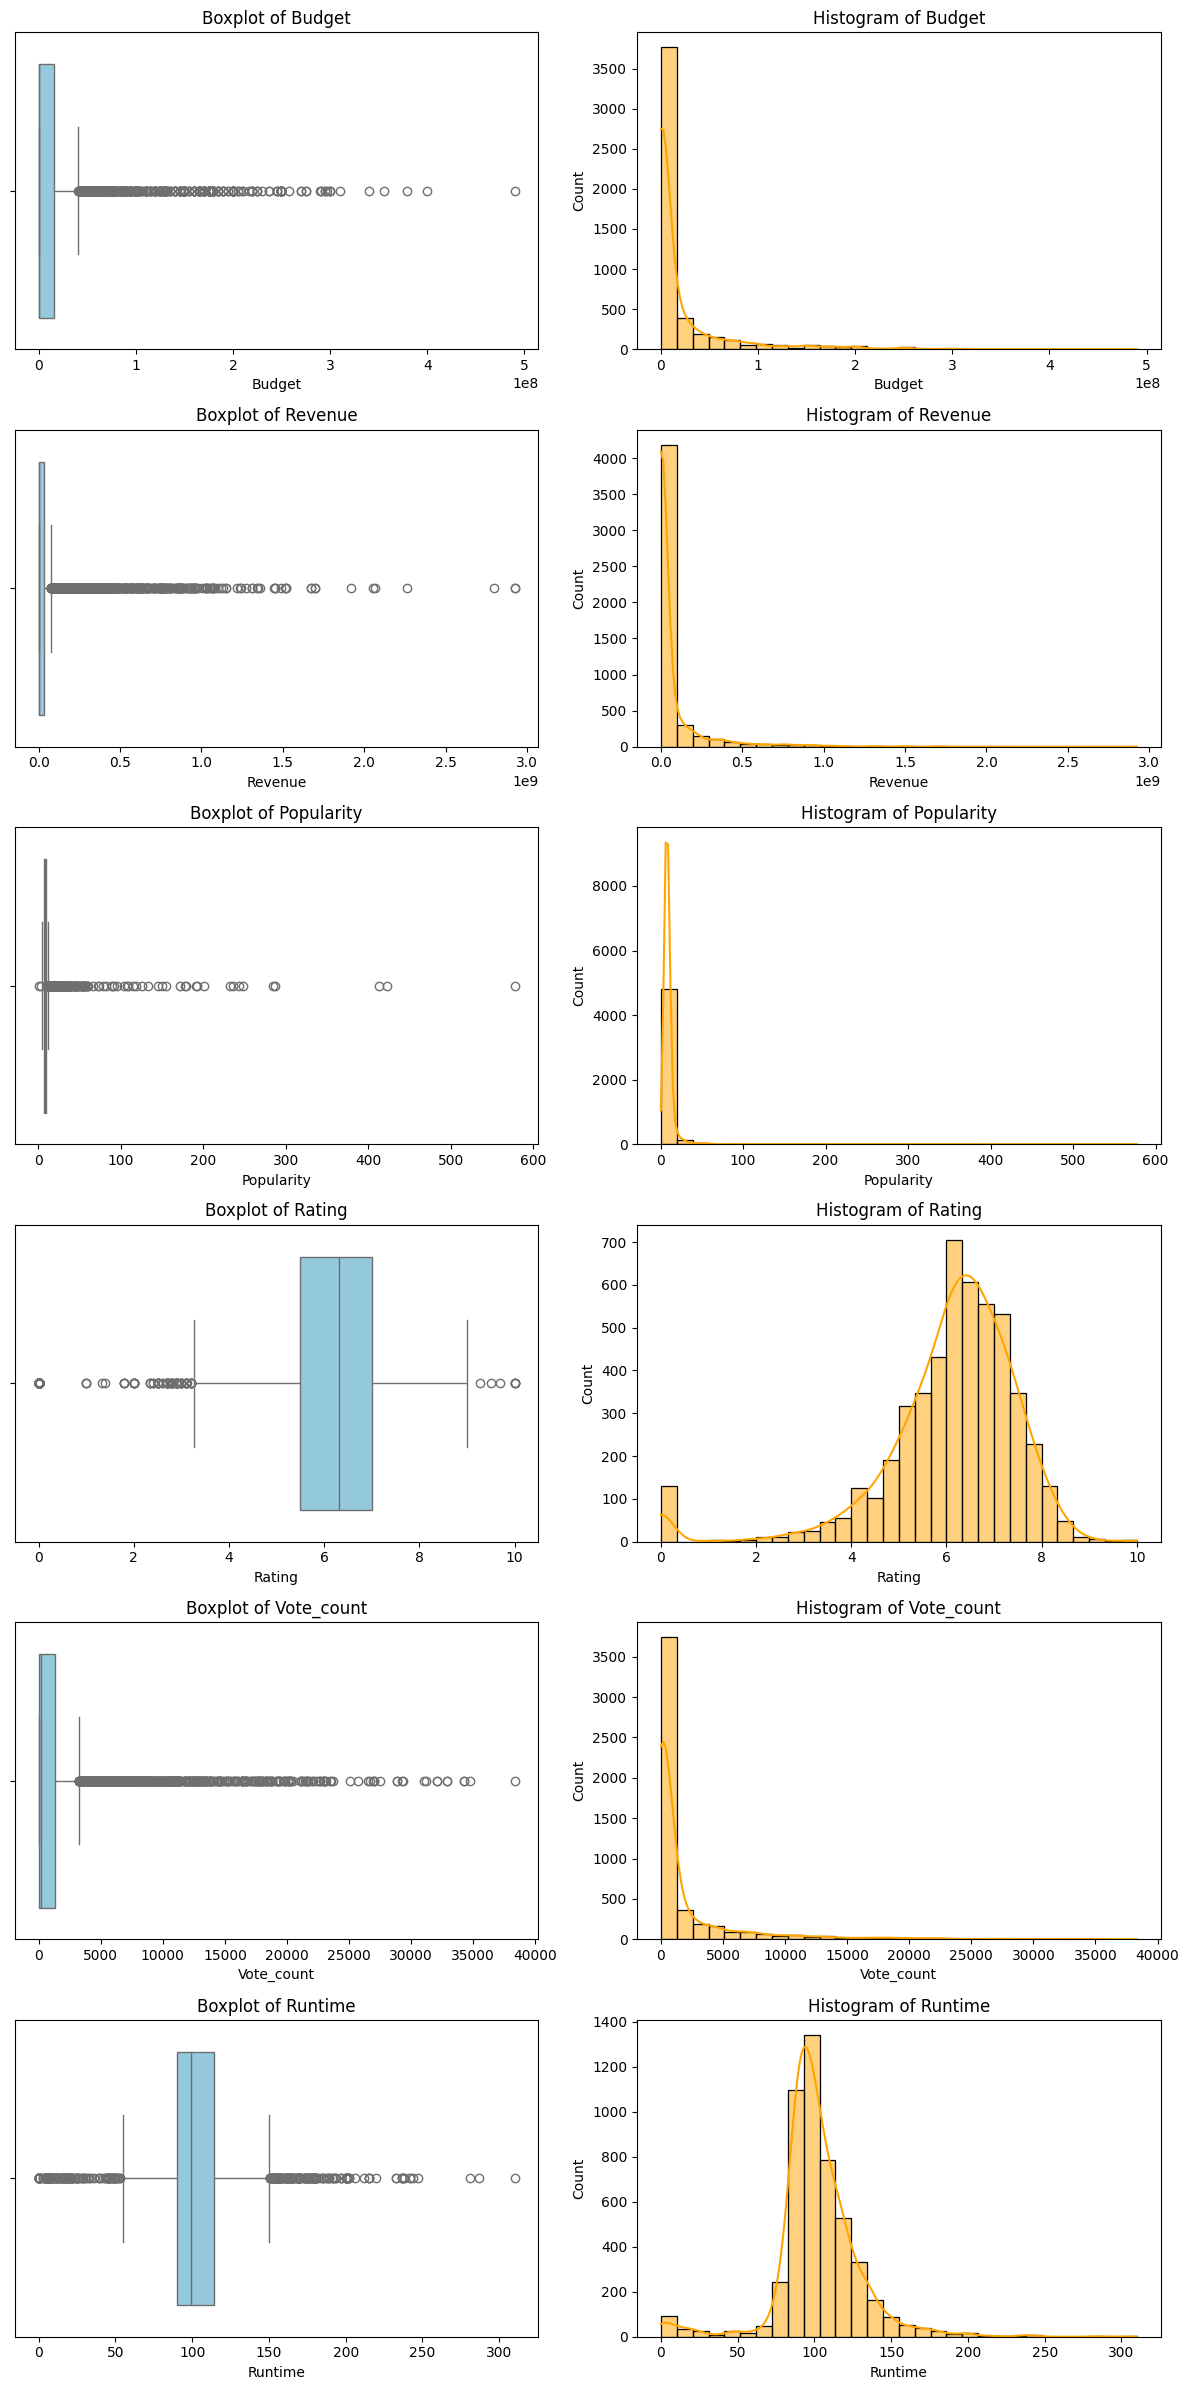

In [18]:
fig, axes = plt.subplots(len(numerical_features), 2, figsize=(12, 4 * len(numerical_features)))

for i, col in enumerate(numerical_features):
    # Boxplot
    sns.boxplot(x=df[col], ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Boxplot of {col}')
    # Histogram
    sns.histplot(df[col], bins=30, ax=axes[i, 1], kde=True, color='orange')
    axes[i, 1].set_title(f'Histogram of {col}')

plt.tight_layout()
plt.show()

**High Budget, high Revenue, high Popularity, high Vote_count outliers are almost always the most successful films.**
Removing them will:
- **Prediction of Success:** For a model to predict Revenue or Popularity, we need the full range of data, especially the extremes, to train the model on what makes a movie successful.
- **Profitability Analysis:** The difference between a low-budget movie and a massive blockbuster is key to understanding profit distribution. Removing blockbusters biases the profit analysis toward the average-performing movies.
- **Exploratory Data Analysis (EDA):** Keeping the extreme data points helps identify the major drivers of the film market.

These Outliers are not errors; they are the interesting and realistic part of the distribution.

In [ ]:
for col in categorical_features:
    print(f"Column {col}:")
    print(df[col].value_counts())
    print("------------------------------")

Column Genres:
Genres
Drama                               376
Comedy                              222
Drama, Romance                      150
Horror, Thriller                    144
Horror                              133
                                   ... 
TV Movie, Drama, Family, Romance      1
War, Drama, History                   1
Animation, Music, Horror, Comedy      1
Drama, Horror, Thriller, Music        1
Crime, Drama, Comedy                  1
Name: count, Length: 1153, dtype: int64
------------------------------
Column Original_language:
Original_language
en    3628
fr     253
it     196
es     171
ja     149
de      56
tl      47
ko      44
id      42
pl      37
no      35
sv      33
pt      33
hi      32
nl      30
zh      29
da      21
tr      18
cn      16
cs      15
fi      14
ta      12
ca      12
hu       9
et       9
te       8
kn       5
ro       5
lt       4
lv       4
ar       3
th       3
fa       2
ru       2
sr       2
is       2
el       2
bm       2
ms   

The `Genres` column should be converted into a clean list. The `Original_language` column has a lot of rare values, which require grouping to reduce noise.

## Data Inspection Summary

After reviewing the dataset, the following issues were identified and should be addressed during data cleaning:

- **Potential duplicates**: Movies with the same attributes may appear multiple times.
- **Inconsistent datatypes**: Some columns have improper types (categorical values stored as `object`).
- **Null Values**: Some columns have a few null values like `Genres` and `Director`.
- **Invalid or Unrealistic Data**: The `Runtime` column contains zero values, which is invalid for a movie and should be removed.
- **Zero Values Representing Missing Data**: Columns like `Budget` , `Revenue` contain zero values, which do not represent real values and should be replaced with the median of the budget/revenue for movies within a similar `Runtime` group.
- **Parse comma-separated genre strings**: Coloumn like `Genres` is a comma-separated string, we can convert it into a clean list of individual genres (multi-label tokenization).
- **Grouping of rare categories**: For languages in `Original_language` column that appear very few times should be grouped into an "other" category to reduce noise.

## Data Cleaning
It is the process of fixing or removing incorrect, corrupted, incorrectly formatted, duplicate, or incomplete data within a dataset. It focuses on fixing the issues found during the data inspection. This step is crucial before moving on to data visualization.

### Dropping Duplicates

In [20]:
duplicates= df.duplicated().sum()
print(f"Number of duplicates: {duplicates}")

Number of duplicates: 1071


In [21]:
df = df.drop_duplicates()
df

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director
Movie_id,,,,,,,,,,
1084242,Zootopia 2,150000000,560333554,577.2135,7.733,286,107,en,"Animation, Family, Comedy, Adventure, Mystery",Jared Bush
533533,TRON: Ares,220000000,142073994,412.9015,6.407,482,119,en,"Science Fiction, Adventure, Action",Joachim Rønning
1419406,The Shadow's Edge,0,174400000,286.3787,6.345,129,142,zh,"Action, Crime, Thriller",Larry Yang
1033462,Bureau 749,0,51706251,235.4213,5.830,47,123,zh,"Action, Adventure, Science Fiction",Lu Chuan
1448560,Wildcat,50000,0,232.0316,6.409,22,99,en,"Action, Thriller, Crime",James Nunn
...,...,...,...,...,...,...,...,...,...,...
323370,The Diabolical,0,0,6.5177,5.012,203,86,en,"Horror, Science Fiction, Thriller",Alistair Legrand
1048771,Christmas Carole,0,0,6.5169,6.156,16,66,en,"Comedy, Drama, Fantasy, TV Movie",Ian Fitzgibbon
84419,House of Horrors,0,0,6.5169,6.027,37,65,en,"Horror, Crime, Thriller",Jean Yarbrough


### Handling Inconsistent Data Types

In [22]:
for col in categorical_features:
    df[col] = df[col].astype('category')

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3929 entries, 1084242 to 9620
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Title              3929 non-null   object  
 1   Budget             3929 non-null   int64   
 2   Revenue            3929 non-null   int64   
 3   Popularity         3929 non-null   float64 
 4   Rating             3929 non-null   float64 
 5   Vote_count         3929 non-null   int64   
 6   Runtime            3929 non-null   int64   
 7   Original_language  3929 non-null   category
 8   Genres             3914 non-null   category
 9   Director           3914 non-null   category
dtypes: category(3), float64(2), int64(4), object(1)
memory usage: 395.2+ KB


### Handling Null values
We inspect missing values on a column-wise basis rather than row-wise. This approach helps us understand how much data is missing in each feature, to avoid dropping rows with meaningful information just because of a single missing value.

In [24]:
null_counts = df.isnull().sum()
null_percentages = (null_counts / len(df)) * 100
null_summary = pd.DataFrame({
    'Null Count': null_counts,
    'Null Percentage': null_percentages
})
null_summary = null_summary[null_summary['Null Count'] > 0]
print(null_summary)

          Null Count  Null Percentage
Genres            15         0.381777
Director          15         0.381777


Since both `Genres` and `Director` column have a small percentage of null values, and movies with no genre or director could be considered invlaid, we can drop the rows that have null values.

In [25]:
null_genres_rows = df[df['Genres'].isnull()]
null_genres_rows

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director
Movie_id,,,,,,,,,,
801945,Final Weapon,0,0,15.6494,0.000,0,15,en,NaN,Stephan Berwick
846369,Perfect Day,0,0,13.6725,0.000,0,8,en,NaN,Paul Wong
490308,Los malvados,0,0,9.3495,5.000,3,90,es,NaN,Alfonso Corona Blake
319691,An Advent Concert of Music by Bach,0,0,7.0297,0.000,0,0,en,NaN,NaN
1564937,Mamasan,0,0,0.4714,6.000,1,75,tl,NaN,Topel Lee
172259,Midnight Man,0,0,7.6826,5.100,8,93,en,NaN,John Weidner
1029529,Powerless King,0,0,8.5610,6.500,2,95,ja,NaN,Kenji Ishiguro
633880,Screen Test [ST263]: Lou Reed,0,0,6.3237,0.000,0,4,en,NaN,Andy Warhol
1158957,How the Ladies Pay (Lou Reed),0,0,6.2002,0.000,0,7,en,NaN,Michael Pilz


In [26]:
null_director_rows = df[df['Director'].isnull()]
null_director_rows

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director
Movie_id,,,,,,,,,,
1553730,Wild Souls,40000,0,22.5257,6.00,1,36,en,Drama,NaN
488968,Sree Hari Hara Sudhan Swami Ayyappan,0,0,16.5983,9.00,3,80,ta,"Animation, Drama, History",NaN
1496735,Genshin Impact: Star Odyssey,0,0,15.1068,0.00,0,3,zh,"Animation, Music",NaN
932624,When a Hot Night Opens 2,0,0,12.9822,6.00,1,83,ko,Drama,NaN
1003348,The Doctor Down Under,0,0,9.2116,0.00,0,51,en,Documentary,NaN
1241752,Rita,0,0,13.0572,6.05,20,113,tl,Drama,NaN
319691,An Advent Concert of Music by Bach,0,0,7.0297,0.00,0,0,en,NaN,NaN
781777,AEW Double or Nothing 2021,0,0,8.0561,6.90,19,237,en,"Action, Drama",NaN
943657,Insane Clown Posse: Hemp Festival,0,0,4.2812,0.00,0,0,en,Music,NaN


In [27]:
null_genres_director_rows =( (df['Genres'].isnull()) | (df['Director'].isnull()) ).sum()
print(f"Number of Null Genres Or Director Rows: {null_genres_director_rows}")

Number of Null Genres Or Director Rows: 27


Then the number of rows that will be dropped since they have either null `Genres` or `Director` rows is 27.

In [28]:
df = df.dropna(subset=['Genres', 'Director'])
df

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director
Movie_id,,,,,,,,,,
1084242,Zootopia 2,150000000,560333554,577.2135,7.733,286,107,en,"Animation, Family, Comedy, Adventure, Mystery",Jared Bush
533533,TRON: Ares,220000000,142073994,412.9015,6.407,482,119,en,"Science Fiction, Adventure, Action",Joachim Rønning
1419406,The Shadow's Edge,0,174400000,286.3787,6.345,129,142,zh,"Action, Crime, Thriller",Larry Yang
1033462,Bureau 749,0,51706251,235.4213,5.830,47,123,zh,"Action, Adventure, Science Fiction",Lu Chuan
1448560,Wildcat,50000,0,232.0316,6.409,22,99,en,"Action, Thriller, Crime",James Nunn
...,...,...,...,...,...,...,...,...,...,...
323370,The Diabolical,0,0,6.5177,5.012,203,86,en,"Horror, Science Fiction, Thriller",Alistair Legrand
1048771,Christmas Carole,0,0,6.5169,6.156,16,66,en,"Comedy, Drama, Fantasy, TV Movie",Ian Fitzgibbon
84419,House of Horrors,0,0,6.5169,6.027,37,65,en,"Horror, Crime, Thriller",Jean Yarbrough


### Invalid or Unrealistic Data
The `Runtime` column contains zero values, which is invalid for a movie and should be removed.

In [29]:
invalid_runtime = (df['Runtime'] < 1).sum()
print(f"Number of Invalid Runtime Rows: {invalid_runtime}")

Number of Invalid Runtime Rows: 36


In [30]:
df = df[df['Runtime'] >= 1]
df

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director
Movie_id,,,,,,,,,,
1084242,Zootopia 2,150000000,560333554,577.2135,7.733,286,107,en,"Animation, Family, Comedy, Adventure, Mystery",Jared Bush
533533,TRON: Ares,220000000,142073994,412.9015,6.407,482,119,en,"Science Fiction, Adventure, Action",Joachim Rønning
1419406,The Shadow's Edge,0,174400000,286.3787,6.345,129,142,zh,"Action, Crime, Thriller",Larry Yang
1033462,Bureau 749,0,51706251,235.4213,5.830,47,123,zh,"Action, Adventure, Science Fiction",Lu Chuan
1448560,Wildcat,50000,0,232.0316,6.409,22,99,en,"Action, Thriller, Crime",James Nunn
...,...,...,...,...,...,...,...,...,...,...
323370,The Diabolical,0,0,6.5177,5.012,203,86,en,"Horror, Science Fiction, Thriller",Alistair Legrand
1048771,Christmas Carole,0,0,6.5169,6.156,16,66,en,"Comedy, Drama, Fantasy, TV Movie",Ian Fitzgibbon
84419,House of Horrors,0,0,6.5169,6.027,37,65,en,"Horror, Crime, Thriller",Jean Yarbrough


### Handling Zero Values Representing Missing Data
Columns like `Budget` , `Revenue` contain zero values, which do not represent real values and should be treated as unknown values.

In [31]:
zero_counts = (df == 0).sum()
zero_percentages = (zero_counts / len(df)) * 100
zero_summary = pd.DataFrame({
    'Zero Count': zero_counts,
    'Zero Percentage': zero_percentages
})
zero_summary = zero_summary[zero_summary['Zero Count'] > 0]
print(zero_summary)

            Zero Count  Zero Percentage
Budget            2116        54.733575
Revenue           2032        52.560786
Rating              64         1.655458
Vote_count          63         1.629591


We check how many unknown values are in `Budget` , `Revenue` columns. Given that 50% of data is missing, we should avoid dropping the columns or a large number of rows, as this leads to substantial data loss and potential bias.

In [32]:
df[numerical_features].describe()

,Budget,Revenue,Popularity,Rating,Vote_count,Runtime
count,3.866000e+03,3.866000e+03,3866.000000,3866.000000,3866.000000,3866.000000
mean,2.102333e+07,7.381428e+07,10.560184,6.151215,1899.042680,103.230729
std,4.704198e+07,2.056004e+08,19.728426,1.389673,4238.677895,25.649242
min,0.000000e+00,0.000000e+00,3.453700,0.000000,0.000000,3.000000
25%,0.000000e+00,0.000000e+00,6.823375,5.545750,28.000000,90.000000
50%,0.000000e+00,0.000000e+00,7.549950,6.327000,162.000000,100.000000
75%,1.750000e+07,3.372863e+07,8.997050,7.003000,1386.250000,114.000000
max,4.899000e+08,2.923706e+09,577.213500,10.000000,38329.000000,310.000000


For the missing/unknown values in the `Budget` aand `Revenue` columns that are zero, we can try to replace the missing values with the median of budget/revenue for movies within a similar `Runtime` group. Since we can expect shorter movies to have a lower budget.

We will define the bins using the statistical analysis from above.

In [33]:
df = df.copy()
df.loc[:, 'runtime_group'] = pd.cut(
    df['Runtime'],
    bins=[0, 60, 90, 120, 150, np.inf],
    labels=['<60', '60-90', '90-120', '120-150', '150+']
)

first, we defined the bins according to groups of similar runtime.

In [34]:
df.loc[:, 'Budget'] = df.groupby('runtime_group', observed=True)['Budget'].transform(
    lambda x: np.where(x == 0, x[x != 0].median().round(0).astype('int64'), x)
)

Then, we fill the missing `Budget` values with median according to runtime groups.

In [35]:
df.loc[:, 'Revenue'] = df.groupby('runtime_group', observed=True)['Revenue'].transform(
    lambda x: np.where(x == 0, x[x != 0].median().round(0).astype('int64'), x)
)

Similarly for `Revenue`, we fill the missing  values with median according to runtime groups.

In [36]:
zero_counts = (df == 0).sum()
zero_percentages = (zero_counts / len(df)) * 100
zero_summary = pd.DataFrame({
    'Zero Count': zero_counts,
    'Zero Percentage': zero_percentages
})
zero_summary = zero_summary[zero_summary['Zero Count'] > 0]
print(zero_summary)

            Zero Count  Zero Percentage
Rating              64         1.655458
Vote_count          63         1.629591


No more zero or unknown values for `Budget` and `Revenue` columns.

In [37]:
df

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director,runtime_group
Movie_id,,,,,,,,,,,
1084242,Zootopia 2,150000000,560333554,577.2135,7.733,286,107,en,"Animation, Family, Comedy, Adventure, Mystery",Jared Bush,90-120
533533,TRON: Ares,220000000,142073994,412.9015,6.407,482,119,en,"Science Fiction, Adventure, Action",Joachim Rønning,90-120
1419406,The Shadow's Edge,43000000,174400000,286.3787,6.345,129,142,zh,"Action, Crime, Thriller",Larry Yang,120-150
1033462,Bureau 749,43000000,51706251,235.4213,5.830,47,123,zh,"Action, Adventure, Science Fiction",Lu Chuan,120-150
1448560,Wildcat,50000,30897398,232.0316,6.409,22,99,en,"Action, Thriller, Crime",James Nunn,90-120
...,...,...,...,...,...,...,...,...,...,...,...
323370,The Diabolical,8350000,9331598,6.5177,5.012,203,86,en,"Horror, Science Fiction, Thriller",Alistair Legrand,60-90
1048771,Christmas Carole,8350000,9331598,6.5169,6.156,16,66,en,"Comedy, Drama, Fantasy, TV Movie",Ian Fitzgibbon,60-90
84419,House of Horrors,8350000,9331598,6.5169,6.027,37,65,en,"Horror, Crime, Thriller",Jean Yarbrough,60-90


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3866 entries, 1084242 to 9620
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Title              3866 non-null   object  
 1   Budget             3866 non-null   int64   
 2   Revenue            3866 non-null   int64   
 3   Popularity         3866 non-null   float64 
 4   Rating             3866 non-null   float64 
 5   Vote_count         3866 non-null   int64   
 6   Runtime            3866 non-null   int64   
 7   Original_language  3866 non-null   category
 8   Genres             3866 non-null   category
 9   Director           3866 non-null   category
 10  runtime_group      3866 non-null   category
dtypes: category(4), float64(2), int64(4), object(1)
memory usage: 394.9+ KB


Notice how a new category was added called `runtime_group`.

In [39]:
df[numerical_features].describe()

,Budget,Revenue,Popularity,Rating,Vote_count,Runtime
count,3.866000e+03,3.866000e+03,3866.000000,3866.000000,3866.000000,3866.000000
mean,3.020210e+07,9.028658e+07,10.560184,6.151215,1899.042680,103.230729
std,4.433432e+07,2.016581e+08,19.728426,1.389673,4238.677895,25.649242
min,3.000000e+00,1.000000e+00,3.453700,0.000000,0.000000,3.000000
25%,8.350000e+06,9.331598e+06,6.823375,5.545750,28.000000,90.000000
50%,1.800000e+07,3.089740e+07,7.549950,6.327000,162.000000,100.000000
75%,2.500000e+07,5.977781e+07,8.997050,7.003000,1386.250000,114.000000
max,4.899000e+08,2.923706e+09,577.213500,10.000000,38329.000000,310.000000


### Parse comma-separated genre strings
Coloumn like `Genres` is a comma-separated string, we can convert it into a clean list of individual genres (multi-label tokenization).

In [40]:
df['Genres'] = df['Genres'].str.split(', ').apply(
    lambda x: [g.strip() for g in x if g.strip()]
)
df

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director,runtime_group
Movie_id,,,,,,,,,,,
1084242,Zootopia 2,150000000,560333554,577.2135,7.733,286,107,en,"[Animation, Family, Comedy, Adventure, Mystery]",Jared Bush,90-120
533533,TRON: Ares,220000000,142073994,412.9015,6.407,482,119,en,"[Science Fiction, Adventure, Action]",Joachim Rønning,90-120
1419406,The Shadow's Edge,43000000,174400000,286.3787,6.345,129,142,zh,"[Action, Crime, Thriller]",Larry Yang,120-150
1033462,Bureau 749,43000000,51706251,235.4213,5.830,47,123,zh,"[Action, Adventure, Science Fiction]",Lu Chuan,120-150
1448560,Wildcat,50000,30897398,232.0316,6.409,22,99,en,"[Action, Thriller, Crime]",James Nunn,90-120
...,...,...,...,...,...,...,...,...,...,...,...
323370,The Diabolical,8350000,9331598,6.5177,5.012,203,86,en,"[Horror, Science Fiction, Thriller]",Alistair Legrand,60-90
1048771,Christmas Carole,8350000,9331598,6.5169,6.156,16,66,en,"[Comedy, Drama, Fantasy, TV Movie]",Ian Fitzgibbon,60-90
84419,House of Horrors,8350000,9331598,6.5169,6.027,37,65,en,"[Horror, Crime, Thriller]",Jean Yarbrough,60-90


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3866 entries, 1084242 to 9620
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Title              3866 non-null   object  
 1   Budget             3866 non-null   int64   
 2   Revenue            3866 non-null   int64   
 3   Popularity         3866 non-null   float64 
 4   Rating             3866 non-null   float64 
 5   Vote_count         3866 non-null   int64   
 6   Runtime            3866 non-null   int64   
 7   Original_language  3866 non-null   category
 8   Genres             3866 non-null   object  
 9   Director           3866 non-null   category
 10  runtime_group      3866 non-null   category
dtypes: category(3), float64(2), int64(4), object(2)
memory usage: 376.3+ KB


Notice how the `Genres` columns now an object instead of a category to store the list.

In [42]:
all_genres = df['Genres'].explode().unique()
print("Unique genres:", sorted(all_genres))
print("Total unique genres:", len(all_genres))

Unique genres: ['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western']
Total unique genres: 19


Now we have a clean and structured list of unique genres.

In [43]:
df['Genres'].explode().value_counts()

Genres
Drama              1622
Comedy             1094
Thriller           1064
Action              931
Horror              608
Romance             582
Adventure           581
Crime               526
Science Fiction     451
Fantasy             389
Family              358
Animation           295
Mystery             283
History             162
TV Movie            157
War                 123
Music               116
Western              92
Documentary          92
Name: count, dtype: int64

This is the count of each value of unique genres in the data.

### Grouping of rare categories
For languages in `Original_language` column that appear very few times should be grouped into an "other" category to reduce noise.


In [44]:
df['Original_language'].value_counts()


Original_language
en    2796
fr     204
it     150
es     135
ja     118
de      44
id      36
ko      35
tl      31
pl      28
sv      26
no      25
hi      25
pt      25
nl      23
zh      21
da      20
tr      13
cn      13
fi      13
cs      11
ta       8
te       7
ca       7
et       6
hu       6
ro       4
th       3
kn       3
lv       3
lt       3
el       2
sr       2
is       2
sh       2
fa       2
ar       2
ms       2
bm       1
bn       1
af       1
ml       1
ht       1
mi       1
sk       1
ru       1
qu       1
tn       1
Name: count, dtype: int64

This is the count of each value of unique languages in the data.

In [45]:
language_map = {
    'en': 'English',
    'fr': 'French',
    'it': 'Italian',
    'es': 'Spanish',
    'ja': 'Japanese',
    'de': 'German',
    'id': 'Indonesian',
    'ko': 'Korean',
    'tl': 'Tagalog',
    'pl': 'Polish',
    'sv': 'Swedish',
    'no': 'Norwegian',
    'hi': 'Hindi',
    'pt': 'Portuguese'
}

First, map the language code into the language name for better readability.

In [46]:
df['Original_language'] = df['Original_language'].map(language_map).fillna('Other')

Fill the `Original_language` column with language name and fill the rest of unselected languages into other.

In [47]:
df['Original_language'].value_counts().sort_values(ascending=False)

Original_language
English       2796
French         204
Other          188
Italian        150
Spanish        135
Japanese       118
German          44
Indonesian      36
Korean          35
Tagalog         31
Polish          28
Swedish         26
Norwegian       25
Hindi           25
Portuguese      25
Name: count, dtype: int64

This is the count of each value of unique languages in the data after grouping the rare languages into other.

In [48]:
df

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director,runtime_group
Movie_id,,,,,,,,,,,
1084242,Zootopia 2,150000000,560333554,577.2135,7.733,286,107,English,"[Animation, Family, Comedy, Adventure, Mystery]",Jared Bush,90-120
533533,TRON: Ares,220000000,142073994,412.9015,6.407,482,119,English,"[Science Fiction, Adventure, Action]",Joachim Rønning,90-120
1419406,The Shadow's Edge,43000000,174400000,286.3787,6.345,129,142,Other,"[Action, Crime, Thriller]",Larry Yang,120-150
1033462,Bureau 749,43000000,51706251,235.4213,5.830,47,123,Other,"[Action, Adventure, Science Fiction]",Lu Chuan,120-150
1448560,Wildcat,50000,30897398,232.0316,6.409,22,99,English,"[Action, Thriller, Crime]",James Nunn,90-120
...,...,...,...,...,...,...,...,...,...,...,...
323370,The Diabolical,8350000,9331598,6.5177,5.012,203,86,English,"[Horror, Science Fiction, Thriller]",Alistair Legrand,60-90
1048771,Christmas Carole,8350000,9331598,6.5169,6.156,16,66,English,"[Comedy, Drama, Fantasy, TV Movie]",Ian Fitzgibbon,60-90
84419,House of Horrors,8350000,9331598,6.5169,6.027,37,65,English,"[Horror, Crime, Thriller]",Jean Yarbrough,60-90


In [49]:
df.to_csv("tmdb_movies_cleaned.csv", index=False)

## Comparison of Dataset Before and After Cleaning

After reviewing the dataset, the following issues were corrected during data cleaning:

- **No Duplicates**: No movies with the same attributes appear multiple times unlike before.
- **No Inconsistent datatypes**: No columns have improper types (categorical values stored as `object`) after cleaning.
- **No more Null Values**: No columns have null values like `Genres` and `Director` after cleaning.
- **No Invalid or Unrealistic Data**: The `Runtime` column no longer contains zero values, which is invalid for a movie.
- **No Zero Values Representing Missing Data**: Columns like `Budget` , `Revenue` no longer contain zero values, which do not represent real values and have been replaced with the median of the budget/revenue for movies within a similar `Runtime` group.
- **Parse comma-separated genre strings**: Coloumn like `Genres` is a comma-separated string, It has been converted into a clean list of individual genres (multi-label tokenization).
- **Grouping of rare categories**: For languages in `Original_language` column that appear very few times, they have been grouped into an "other" category to reduce noise.

## Data Visualization
It is the process of representing data visually to help understand it better. It involves transforming abstract, numerical, or textual data into a visual context, such as graphs, charts, maps, and other graphical formats. This visualization makes it easier to see patterns, trends, and outliers in data, facilitating better analysis, decision-making, and communication of insights. 

In [50]:
df = pd.read_csv("tmdb_movies_cleaned.csv")
df.head()

,Title,Budget,Revenue,Popularity,Rating,Vote_count,Runtime,Original_language,Genres,Director,runtime_group
0,Zootopia 2,150000000,560333554,577.2135,7.733,286,107,English,"['Animation', 'Family', 'Comedy', 'Adventure',...",Jared Bush,90-120
1,TRON: Ares,220000000,142073994,412.9015,6.407,482,119,English,"['Science Fiction', 'Adventure', 'Action']",Joachim Rønning,90-120
2,The Shadow's Edge,43000000,174400000,286.3787,6.345,129,142,Other,"['Action', 'Crime', 'Thriller']",Larry Yang,120-150
3,Bureau 749,43000000,51706251,235.4213,5.830,47,123,Other,"['Action', 'Adventure', 'Science Fiction']",Lu Chuan,120-150
4,Wildcat,50000,30897398,232.0316,6.409,22,99,English,"['Action', 'Thriller', 'Crime']",James Nunn,90-120


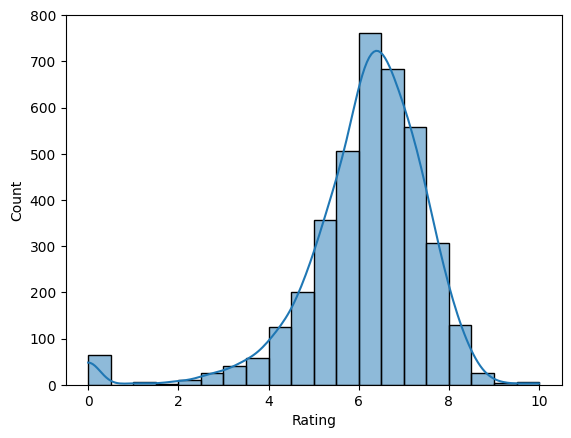

In [51]:
sns.histplot(df["Rating"], bins=20, kde=True)
plt.show()

You can see the distribution of ratings clearly:
Where most ratings are concentrated.
If the distribution is skewed (more ratings at the low or high end).
Peaks (modes) in ratings.
The KDE line helps identify patterns not obvious from bars alone.
Adjusting bins can make the histogram more or less detailed.
This plot is useful for data exploration before analysis or modeling.

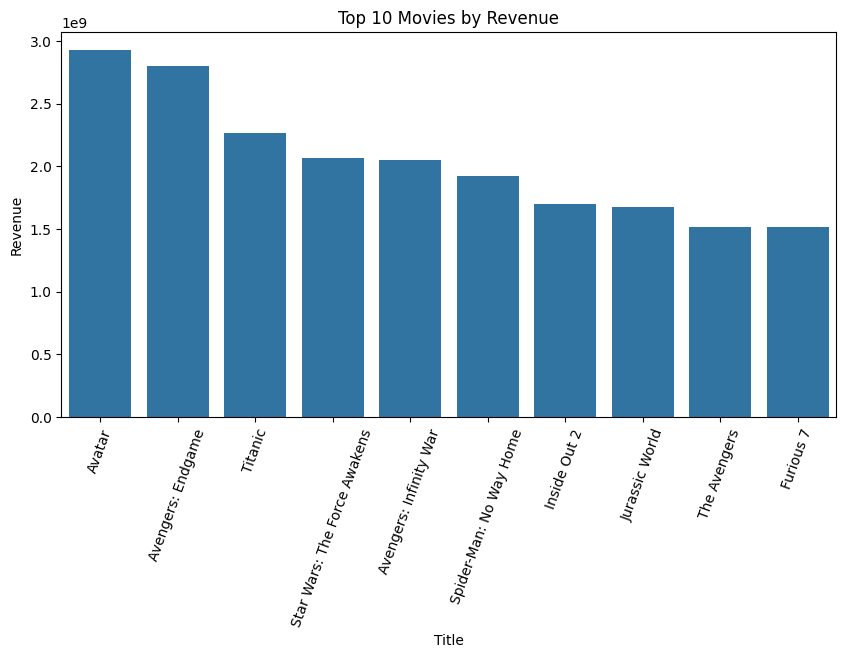

In [52]:
top_rev = df.nlargest(10, "Revenue")

plt.figure(figsize=(10,5))
sns.barplot(data=top_rev, x="Title", y="Revenue")
plt.xticks(rotation=70)
plt.title("Top 10 Movies by Revenue")
plt.show()

Highlights which movies generated the highest revenue in the dataset.

Shows revenue gaps, helping identify dominance or balance among top earners.

Helps reveal whether one movie significantly outperformed others.

Useful for further comparisons with budget, rating, genre, or release year.

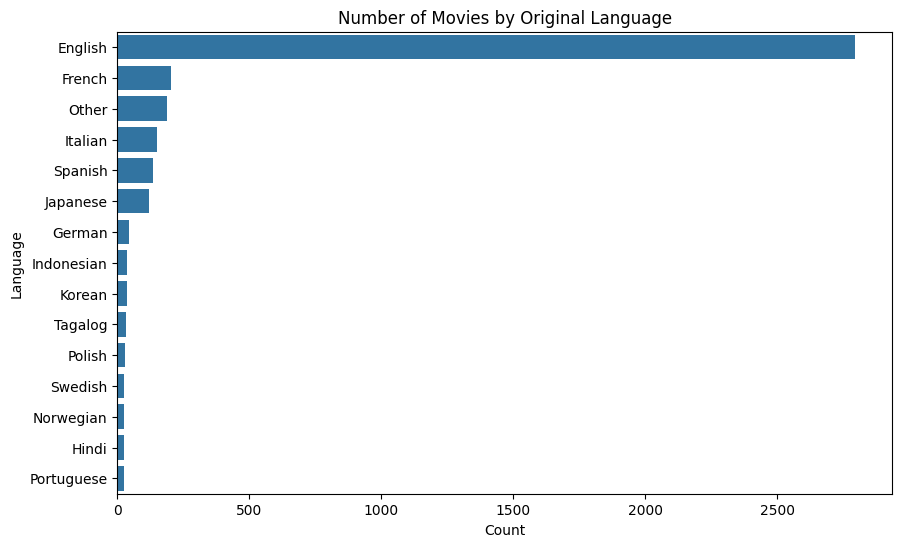

In [53]:
lang_counts = df["Original_language"].value_counts()

plt.figure(figsize=(10,6))
sns.barplot(y=lang_counts.index, x=lang_counts.values)
plt.title("Number of Movies by Original Language")
plt.xlabel("Count")
plt.ylabel("Language")
plt.show()

Shows which languages appear most frequently in the dataset.

Highlights whether a few languages dominate or if the dataset is diverse.

Longer bars indicate languages with higher movie production volumes.

Helps guide analysis on language relations with ratings, revenue, or genres.

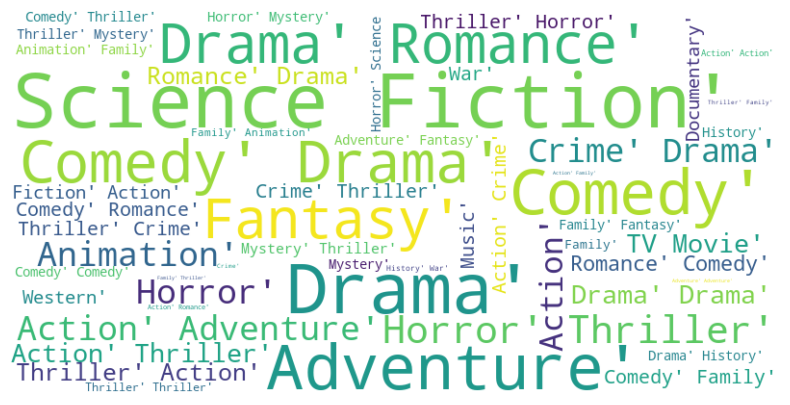

In [54]:
text = " ".join(df["Genres"].astype(str))

wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

Displays the most common genres, where larger words appear more frequently.

Quickly reveals dominant and less represented genre categories.

Gives an instant overview of genre diversity in the dataset.

Helps identify patterns before performing numeric genre analysis.

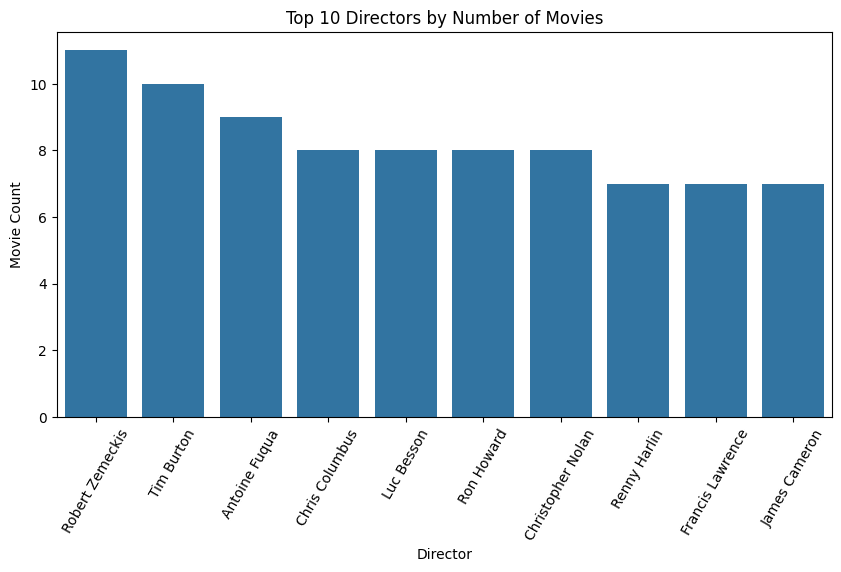

In [55]:
top_directors = df["Director"].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_directors.index, y=top_directors.values)
plt.xticks(rotation=60)
plt.title("Top 10 Directors by Number of Movies")
plt.ylabel("Movie Count")
plt.show()

Shows which directors have the highest number of films in the dataset.

Highlights whether one director is significantly more productive than others.

Reveals patterns in director activity and output.

Useful for linking director counts with ratings, revenue, or genres.

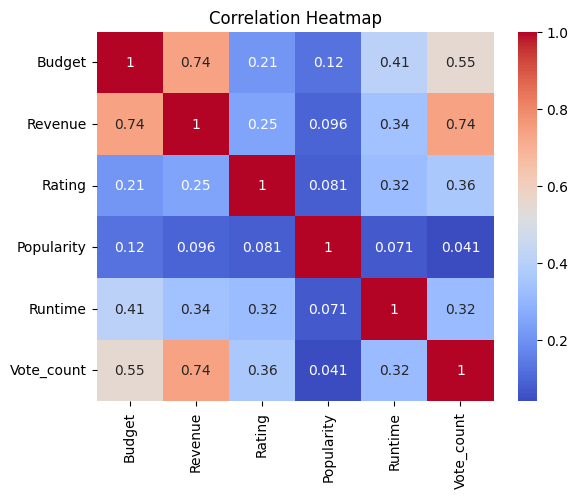

In [56]:
sns.heatmap(df[['Budget','Revenue','Rating','Popularity','Runtime','Vote_count']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Strong positive correlation between Budget and Revenue → spending more usually leads to higher earnings.

Revenue is also linked to Popularity and Vote_count → popular movies and those with more engagement perform better.

Rating and Runtime show weak correlation, meaning they do not predict financial performance.

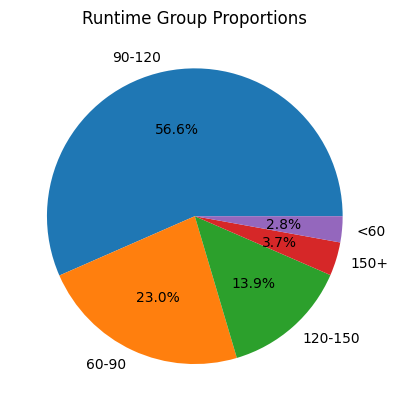

In [57]:
# Generate counts for runtime groups
runtime_counts = df['runtime_group'].value_counts()

# Pie Chart
plt.pie(runtime_counts.values, labels=runtime_counts.index, autopct='%1.1f%%')
plt.title('Runtime Group Proportions')
plt.show()

Most movies fall in the medium runtime category (depending on your data).

Only a smaller percentage are very short or very long.

This means filmmakers follow a standard runtime range, likely based on audience preference and cinema format.

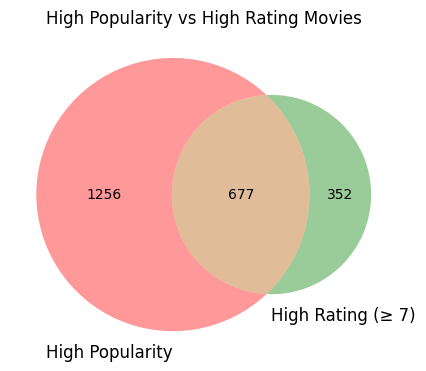

In [58]:
high_pop = set(df[df["Popularity"] > df["Popularity"].median()].index)
high_rating = set(df[df["Rating"] >= 7].index)

plt.figure(figsize=(5,5))
venn2(
    subsets = (len(high_pop - high_rating),
               len(high_rating - high_pop),
               len(high_pop & high_rating)),
    set_labels = ("High Popularity", "High Rating (≥ 7)")
)
plt.title("High Popularity vs High Rating Movies")
plt.show()

Shows how many movies are only highly popular, only highly rated, or both.

The overlap reveals movies that achieve both commercial popularity and strong audience ratings.

Highlights whether popularity and rating tend to align or differ in your dataset.

Useful for identifying standout movies that succeed on both metrics

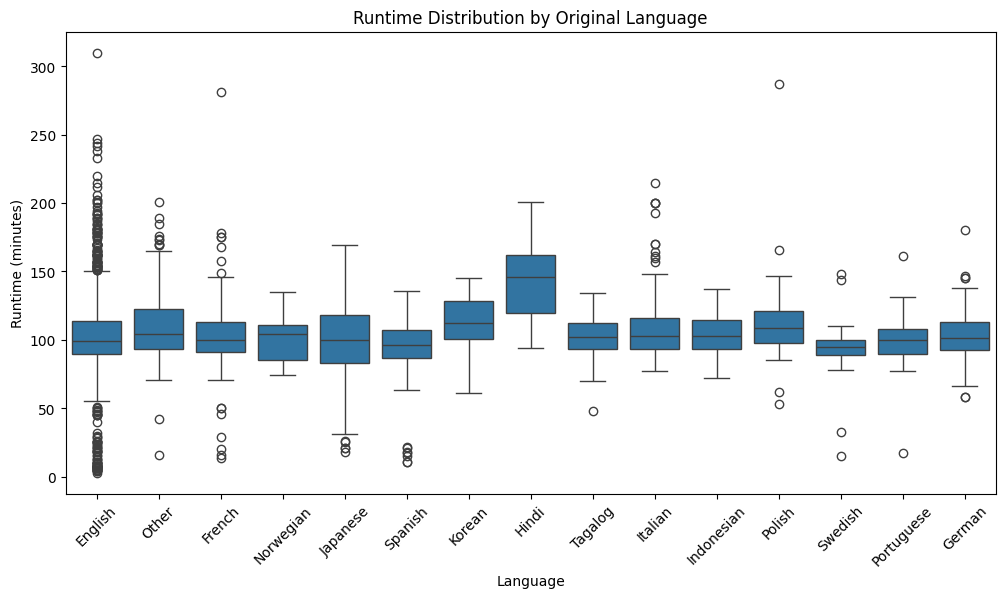

In [59]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x="Original_language", y="Runtime")
plt.title("Runtime Distribution by Original Language")
plt.xlabel("Language")
plt.ylabel("Runtime (minutes)")
plt.xticks(rotation=45)
plt.show()

Shows how movie runtime varies across different languages.

The median line indicates the typical runtime for each language group.

The spread (IQR) reveals whether runtimes are consistent or widely varied.

Outliers highlight unusually long or short movies within each language category

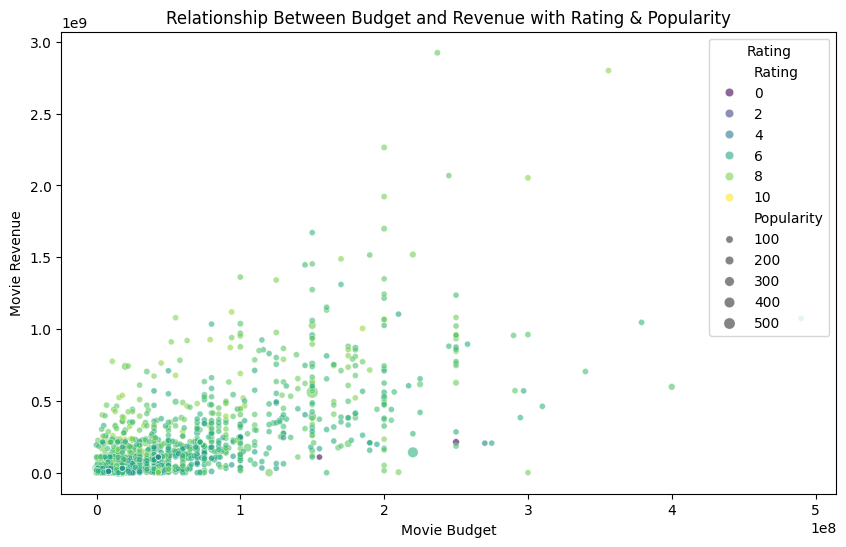

In [60]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    x='Budget',
    y='Revenue',
    hue='Rating',
    size='Popularity',
    data=df,
    palette='viridis',
    alpha=0.6
)

plt.title('Relationship Between Budget and Revenue with Rating & Popularity')
plt.xlabel('Movie Budget')
plt.ylabel('Movie Revenue')
plt.legend(title='Rating')
plt.show()

Movies with higher budgets mostly fall in the high‑revenue area → investment increases financial return.

Larger points (representing high popularity) are often the most successful movies.

Rating colors do not form a clear trend → high rating does not guarantee high earnings.

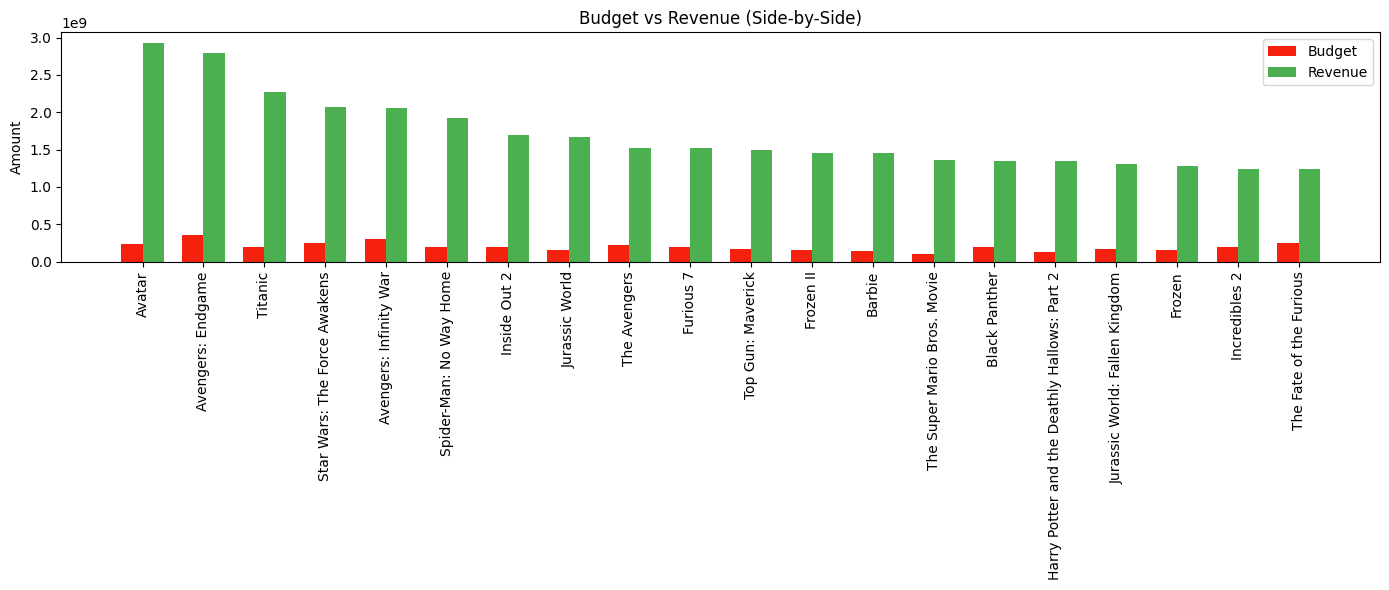

In [64]:
df_sorted = df.sort_values("Revenue", ascending=False).head(20)

budget  = df_sorted["Budget"]
revenue = df_sorted["Revenue"]

x = np.arange(len(df_sorted))
width = 0.35

plt.figure(figsize=(14,6))

plt.bar(x - width/2, budget, width, label="Budget", color="#F5210E")   
plt.bar(x + width/2, revenue, width, label="Revenue", color="#4CAF50")  

plt.xticks(x, df_sorted["Title"], rotation=90)
plt.ylabel("Amount")
plt.title("Budget vs Revenue (Side-by-Side)")
plt.legend()
plt.tight_layout()
plt.show()

Compares each movie’s budget to its revenue to show profitability at a glance.

Movies where the revenue bar is much higher indicate strong financial success.

Helps identify titles that underperformed or failed to recover production costs.

Useful for analyzing financial patterns and comparing investment vs return.

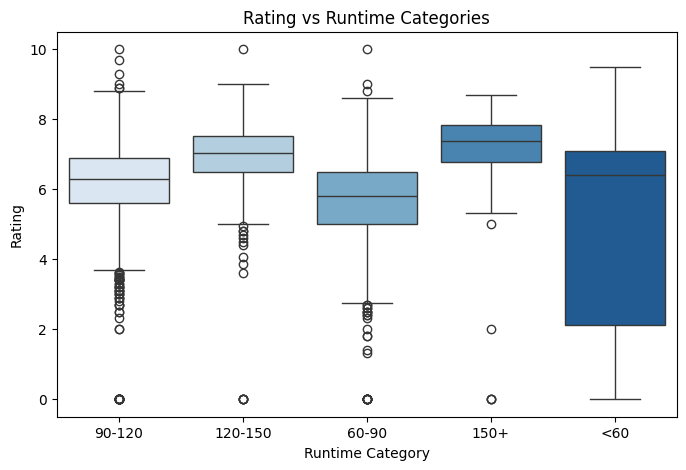

In [65]:
plt.figure(figsize=(8,5))
sns.boxplot(x='runtime_group', y='Rating', data=df, palette="Blues", hue='runtime_group', legend=False)
plt.title('Rating vs Runtime Categories')
plt.xlabel('Runtime Category')
plt.ylabel('Rating')
plt.show()

Ratings are similar across all runtime groups.

Even longer movies do not guarantee higher ratings.

The variation (spread) shows that some movies in each category can be rated high or low regardless of runtime.


## Regression Model
A regression model is a statistical tool that quantifies the relationship between a dependent variable (outcome) and one or more independent variables (predictors) to understand, predict, or infer patterns in data, often visualized as a "best-fit" line or curve through data points. It helps determine the strength and direction of relationships. It is used for predicting the rating and profit of a movie. 

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# Load dataset
df = pd.read_csv("tmdb_movies_cleaned.csv")

# Create Profit column
df['Profit'] = df['Revenue'] - df['Budget']

# Features for rating prediction
features_rating = ['Genres', 'Runtime', 'Budget', 'Popularity', 'Vote_count', 'Original_language']
target_rating = 'Rating'

# Features for profit prediction
features_profit = ['Genres', 'Runtime', 'Budget', 'Popularity', 'Vote_count', 'Original_language']
target_profit = 'Profit'

# Preprocessing: One-hot encode categorical features
categorical_features = ['Genres', 'Original_language']
numerical_features = ['Runtime', 'Budget', 'Popularity', 'Vote_count']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numerical_features)
    ]
)

# Function to train and evaluate a model
def train_and_evaluate(X, y, model_name):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model_name)])
    pipeline.fit(X_train, y_train)
    
    y_pred = pipeline.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    return mae, rmse, r2

# Train and evaluate models
# Rating prediction
mae_lr_rating, rmse_lr_rating, r2_lr_rating = train_and_evaluate(df[features_rating], df[target_rating], LinearRegression())
mae_rf_rating, rmse_rf_rating, r2_rf_rating = train_and_evaluate(df[features_rating], df[target_rating], RandomForestRegressor(n_estimators=100, random_state=42))

# Profit prediction
mae_lr_profit, rmse_lr_profit, r2_lr_profit = train_and_evaluate(df[features_profit], df[target_profit], LinearRegression())
mae_rf_profit, rmse_rf_profit, r2_rf_profit = train_and_evaluate(df[features_profit], df[target_profit], RandomForestRegressor(n_estimators=100, random_state=42))

# Train pipelines for rating and profit
pipeline_rating_lr = Pipeline(steps=[('preprocessor', preprocessor), ('model', LinearRegression())])
pipeline_rating_rf = Pipeline(steps=[('preprocessor', preprocessor), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])
pipeline_profit_lr = Pipeline(steps=[('preprocessor', preprocessor), ('model', LinearRegression())])
pipeline_profit_rf = Pipeline(steps=[('preprocessor', preprocessor), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])

# Fit them
pipeline_rating_rf.fit(df[features_rating], df[target_rating])
pipeline_profit_rf.fit(df[features_profit], df[target_profit])

# Function for predicting rating and profit
def predict_movie_rating_and_profit(movie_details, pipeline_rating, pipeline_profit):
    new_movie = pd.DataFrame([movie_details])
    predicted_rating = pipeline_rating.predict(new_movie)[0]
    predicted_profit = pipeline_profit.predict(new_movie)[0]
    return predicted_rating, predicted_profit

In [3]:
print("Rating Prediction:")
print(f"Linear Regression")
print(f"MAE: {mae_lr_rating:.2f}, RMSE: {rmse_lr_rating:.2f}, R^2: {r2_lr_rating:.2f}")
print(f"Random Forest")
print(f"MAE: {mae_rf_rating:.2f}, RMSE: {rmse_rf_rating:.2f}, R^2: {r2_rf_rating:.2f}\n")

print("Profit Prediction:")
print(f"Linear Regression")
print(f"MAE: {mae_lr_profit:.2f}, RMSE: {rmse_lr_profit:.2f}, R^2: {r2_lr_profit:.2f}")
print(f"Random Forest")
print(f"MAE: {mae_rf_profit:.2f}, RMSE: {rmse_rf_profit:.2f}, R^2: {r2_rf_profit:.2f}\n")

Rating Prediction:
Linear Regression
MAE: 0.85, RMSE: 1.18, R^2: 0.16
Random Forest
MAE: 0.65, RMSE: 0.91, R^2: 0.50

Profit Prediction:
Linear Regression
MAE: 53415036.75, RMSE: 113297394.22, R^2: 0.60
Random Forest
MAE: 43263750.22, RMSE: 106718157.06, R^2: 0.64



MAE, RMSE, and R² are regression metrics: MAE (Mean Absolute Error) measures average absolute error (lower is better, same units as data); RMSE (Root Mean Squared Error) penalizes large errors more (lower is better, same units); and R² (Coefficient of Determination) shows proportion of variance explained (0 to 1, closer to 1 is better), indicating model fit.

In [4]:
movie_example = {
    'Genres': 'Action, Drama',
    'Runtime': 120,
    'Budget': 150000000,
    'Popularity': 80,
    'Vote_count': 10000,
    'Original_language': 'English'
}

pred_rating, pred_profit = predict_movie_rating_and_profit(movie_example, pipeline_rating_rf, pipeline_profit_rf)
print(f"Predicted Rating: {pred_rating:.2f}")
print(f"Predicted Profit: ${pred_profit:,.2f}")

Predicted Rating: 7.39
Predicted Profit: $639,503,579.74
